In [1]:

# Step 1: Import Libraries

!pip -q install kagglehub

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from PIL import Image

import torch
from torch import nn
from torchvision import transforms
import kagglehub

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("All libraries loaded successfully!")


PyTorch Version: 2.14.1+cu130
Device: cuda
All libraries loaded successfully!


In [2]:

# Step 2: Download Dataset

dataset_path = kagglehub.dataset_download(
    "divg07/casia-20-image-tampering-detection-dataset"
)

data_dir = Path(dataset_path) / "CASIA2"

print("Dataset downloaded successfully!")
print("Dataset Path:", data_dir)
print("Dataset exists:", data_dir.exists())

print("\nDataset Folders:")
for folder in sorted(data_dir.iterdir()):
    print("-", folder.name)


100%|██████████| 2.56G/2.56G [00:20<00:00, 131MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset Path: /root/.cache/kagglehub/datasets/divg07/casia-20-image-tampering-detection-dataset/versions/1/CASIA2
Dataset exists: True

Dataset Folders:
- Au
- CASIA 2 Groundtruth
- Tp


In [3]:

# Step 3: Explore Dataset

extensions = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():

        images = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in extensions
        ]

        print("Folder:", folder.name)
        print("Number of images:", len(images))
        print("-" * 35)


Folder: Au
Number of images: 7491
-----------------------------------
Folder: CASIA 2 Groundtruth
Number of images: 5123
-----------------------------------
Folder: Tp
Number of images: 5123
-----------------------------------


In [4]:

# Step 4: Create DataFrame

records = []

for folder_name, label in [("Au", 0), ("Tp", 1)]:

    folder = data_dir / folder_name

    for path in folder.rglob("*"):

        if path.is_file() and path.suffix.lower() in extensions:

            records.append({
                "image_path": str(path),
                "label": label,
                "class_name": (
                    "Authentic" if label == 0
                    else "Tampered"
                )
            })

df = pd.DataFrame(records)

print("Dataset prepared successfully!")
print("Total images:", len(df))

print("\nClass Distribution:")
print(df["class_name"].value_counts())

display(df.head())


Dataset prepared successfully!
Total images: 12614

Class Distribution:
class_name
Authentic    7491
Tampered     5123
Name: count, dtype: int64


,image_path,label,class_name
0,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,Authentic
1,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,Authentic
2,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,Authentic
3,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,Authentic
4,/root/.cache/kagglehub/datasets/divg07/casia-2...,0,Authentic


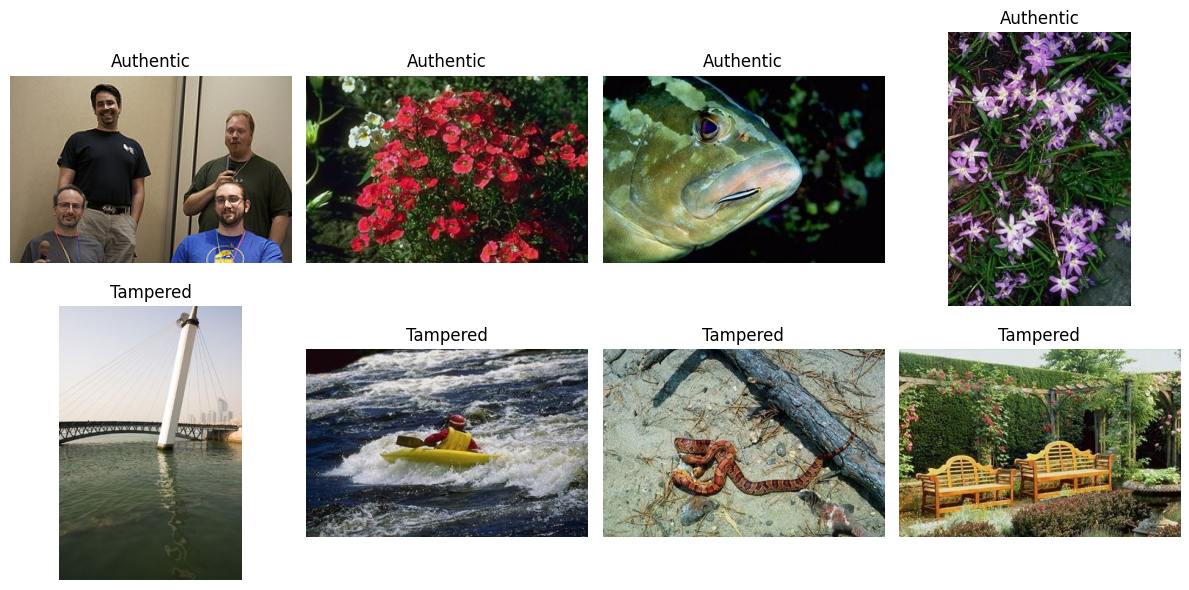

In [5]:

# Step 5: Visualize Dataset

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate([0, 1]):

    samples = df[df["label"] == label].sample(
        n=4,
        random_state=42
    )

    for col, (_, sample) in enumerate(samples.iterrows()):

        with Image.open(sample["image_path"]) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(sample["class_name"])
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


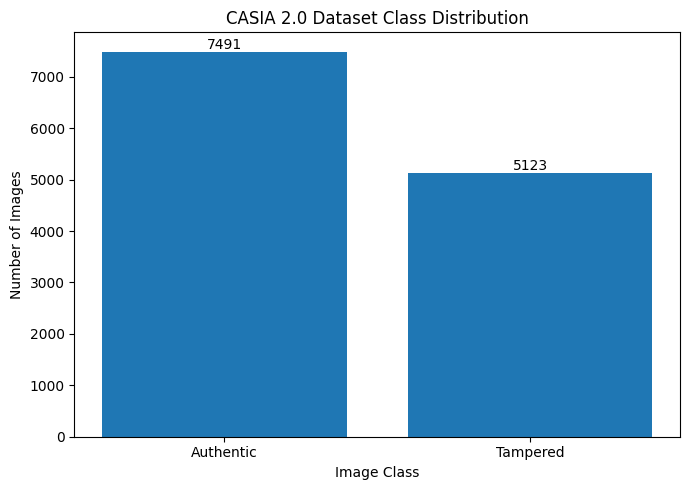

In [6]:

# Step 6: Class Distribution

class_counts = df["class_name"].value_counts()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("CASIA 2.0 Dataset Class Distribution")
plt.xlabel("Image Class")
plt.ylabel("Number of Images")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [8]:

# Step 7A: Prepare JPEG Dataset and Source Groups

import re
import pandas as pd
from pathlib import Path

# Keep JPEG images only
jpg_df = df[
    df["image_path"].str.lower().str.endswith((".jpg", ".jpeg"))
].copy().reset_index(drop=True)

parent = list(range(len(jpg_df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

source_owner = {}

for i, path in enumerate(jpg_df["image_path"]):
    filename = Path(path).stem.lower()

    source_ids = set(
        re.findall(r"([a-z]{3})_?(\d{5})", filename)
    )

    for source_id in source_ids:
        if source_id in source_owner:
            union(i, source_owner[source_id])
        else:
            source_owner[source_id] = i

jpg_df["group_id"] = [
    find(i) for i in range(len(jpg_df))
]

print("JPEG Dataset Prepared!")
print("Total JPEG Images:", len(jpg_df))
print("Total Source Groups:", jpg_df["group_id"].nunique())



JPEG Dataset Prepared!
Total JPEG Images: 9501
Total Source Groups: 6937


In [11]:

# Step 7B: Split Dataset

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

data = jpg_df.copy().reset_index(drop=True)

best_score = float("inf")
best_indices = None

for seed in range(200):

    splitter1 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=seed
    )

    dev_idx, test_idx = next(
        splitter1.split(data, groups=data["group_id"])
    )

    dev = data.iloc[dev_idx]

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15 / 0.85,
        random_state=seed + 1000
    )

    tr_local, va_local = next(
        splitter2.split(dev, groups=dev["group_id"])
    )

    train_idx = dev_idx[tr_local]
    val_idx = dev_idx[va_local]

    parts = [
        data.iloc[train_idx],
        data.iloc[val_idx],
        data.iloc[test_idx]
    ]

    target_ratios = np.array([0.70, 0.15, 0.15])
    overall_rate = data["label"].mean()

    ratios = np.array([
        len(p) / len(data) for p in parts
    ])

    rates = np.array([
        p["label"].mean() for p in parts
    ])

    score = (
        np.abs(ratios - target_ratios).sum()
        + 2 * np.abs(rates - overall_rate).sum()
    )

    if score < best_score:
        best_score = score
        best_indices = (
            train_idx.copy(),
            val_idx.copy(),
            test_idx.copy()
        )

train_idx, val_idx, test_idx = best_indices

train_df = data.iloc[train_idx].copy()
val_df = data.iloc[val_idx].copy()
test_df = data.iloc[test_idx].copy()

assert set(train_df["group_id"]).isdisjoint(val_df["group_id"])
assert set(train_df["group_id"]).isdisjoint(test_df["group_id"])
assert set(val_df["group_id"]).isdisjoint(test_df["group_id"])

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nDataset split completed successfully!")


Training: 7120
Validation: 1158
Testing: 1223

Dataset split completed successfully!


In [12]:

# Step 8: Prepare PyTorch DataLoaders

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

class ForgeryDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = int(row["label"])

        return image, label

train_dataset = ForgeryDataset(
    train_df, train_transform
)

val_dataset = ForgeryDataset(
    val_df, test_transform
)

test_dataset = ForgeryDataset(
    test_df, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("DataLoaders created successfully!")


Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
DataLoaders created successfully!


In [13]:

# Step 9: Build Custom CNN Model

import torch
from torch import nn

class ForgeryCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = ForgeryCNN().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal Parameters:", total_params)
print("CNN Model created successfully!")


ForgeryCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

Total Parameters: 101634
CNN Model created successfully!


In [14]:

# Step 10: Train Custom CNN

import torch
import numpy as np
from torch import nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Calculate class weights from training data only
class_counts = np.bincount(
    train_df["label"].to_numpy(), minlength=2
)

weights = len(train_df) / (2 * class_counts)
class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
val_f1_scores = []

best_val_f1 = -1
best_state = None

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0
    train_preds = []
    train_labels = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_preds.extend(outputs.argmax(1).cpu().tolist())
        train_labels.extend(labels.cpu().tolist())

    train_loss = running_loss / len(train_dataset)
    train_acc = accuracy_score(train_labels, train_preds)

    # Validation
    model.eval()
    running_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * labels.size(0)
            val_preds.extend(outputs.argmax(1).cpu().tolist())
            val_labels.extend(labels.cpu().tolist())

    val_loss = running_val_loss / len(val_dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(
        val_labels, val_preds,
        pos_label=1, zero_division=0
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val F1: {val_f1:.4f}"
    )

# Restore the best validation model
model.load_state_dict(best_state)

torch.save(model.state_dict(), "/content/best_custom_cnn.pth")

print("\nTraining completed successfully!")
print(f"Best Validation F1: {best_val_f1:.4f}")
print("Best model saved!")


Epoch [1/5] | Train Loss: 0.6827 | Train Acc: 57.42% | Val Loss: 0.6643 | Val Acc: 58.81% | Val F1: 0.1902
Epoch [2/5] | Train Loss: 0.6730 | Train Acc: 60.66% | Val Loss: 0.6063 | Val Acc: 73.75% | Val F1: 0.2124
Epoch [3/5] | Train Loss: 0.6701 | Train Acc: 61.28% | Val Loss: 0.6621 | Val Acc: 64.59% | Val F1: 0.1961
Epoch [4/5] | Train Loss: 0.6664 | Train Acc: 61.43% | Val Loss: 0.5177 | Val Acc: 81.52% | Val F1: 0.2357
Epoch [5/5] | Train Loss: 0.6626 | Train Acc: 63.06% | Val Loss: 0.6938 | Val Acc: 54.84% | Val F1: 0.1764

Training completed successfully!
Best Validation F1: 0.2357
Best model saved!


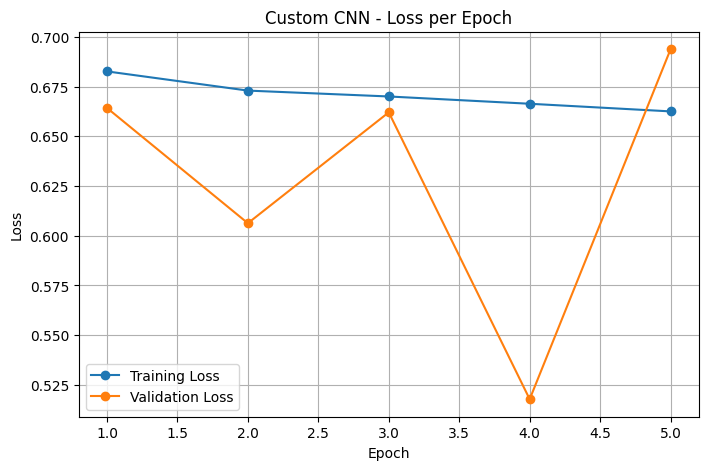

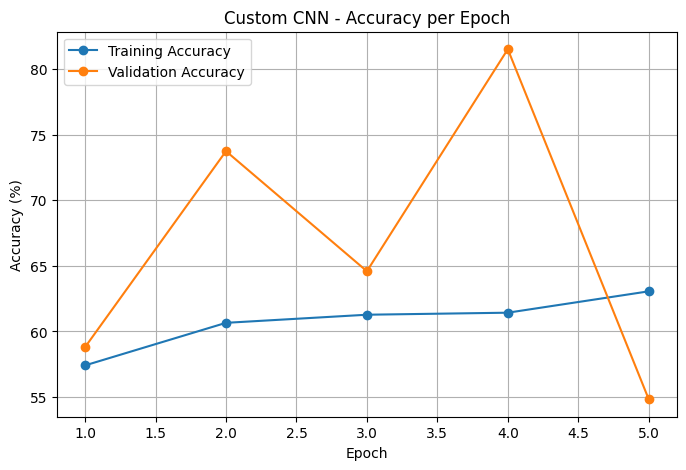

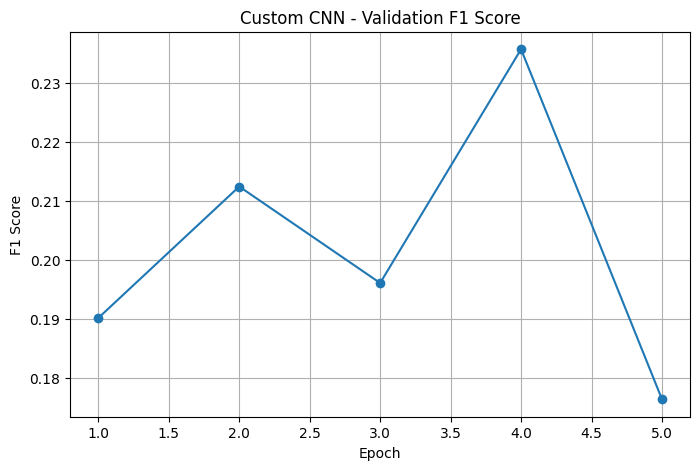

In [15]:

# Step 11: Training and Validation Graphs

epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, train_losses, marker="o", label="Training Loss")
plt.plot(epoch_numbers, val_losses, marker="o", label="Validation Loss")
plt.title("Custom CNN - Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epoch_numbers,
    np.array(train_accuracies) * 100,
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    epoch_numbers,
    np.array(val_accuracies) * 100,
    marker="o",
    label="Validation Accuracy"
)
plt.title("Custom CNN - Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, val_f1_scores, marker="o")
plt.title("Custom CNN - Validation F1 Score")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.grid(True)
plt.show()


Classification Report:
              precision    recall  f1-score   support

   Authentic       0.92      0.87      0.89      1047
    Tampered       0.20      0.30      0.24       111

    accuracy                           0.82      1158
   macro avg       0.56      0.58      0.57      1158
weighted avg       0.85      0.82      0.83      1158

Balanced Accuracy: 0.5837
ROC-AUC: 0.5484


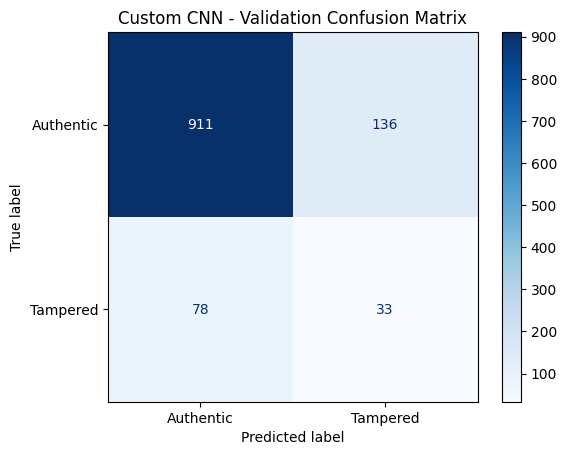

In [16]:

# Step 12: Custom CNN Validation Evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score
)
import numpy as np
import matplotlib.pyplot as plt
import torch

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

print("Classification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Authentic", "Tampered"],
    zero_division=0
))

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(
        all_labels, all_predictions
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        all_labels, all_probabilities
    ), 4)
)

cm = confusion_matrix(
    all_labels, all_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Authentic", "Tampered"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Custom CNN - Validation Confusion Matrix")
plt.show()


In [17]:

# Step 13: Verify Current Dataset Split

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(subset)} images")
    print(subset["class_name"].value_counts())
    print("Tampered %:",
          round(subset["label"].mean() * 100, 2))

print("\nDataLoader sizes:")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

print("\nSource group overlap:")
print("Train-Val:",
      len(set(train_df["group_id"]) &
          set(val_df["group_id"])))
print("Train-Test:",
      len(set(train_df["group_id"]) &
          set(test_df["group_id"])))
print("Val-Test:",
      len(set(val_df["group_id"]) &
          set(test_df["group_id"])))



Training: 7120 images
class_name
Authentic    5321
Tampered     1799
Name: count, dtype: int64
Tampered %: 25.27

Validation: 1158 images
class_name
Authentic    1047
Tampered      111
Name: count, dtype: int64
Tampered %: 9.59

Testing: 1223 images
class_name
Authentic    1069
Tampered      154
Name: count, dtype: int64
Tampered %: 12.59

DataLoader sizes:
Train: 7120
Validation: 1158
Test: 1223

Source group overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [18]:

# Step 14: Investigate Large Source Group

from pathlib import Path
import pandas as pd

group_sizes = (
    jpg_df.groupby("group_id")
    .size()
    .sort_values(ascending=False)
)

largest_group_id = group_sizes.index[0]

large_group = jpg_df[
    jpg_df["group_id"] == largest_group_id
].copy()

print("Largest Group ID:", largest_group_id)
print("Number of Images:", len(large_group))

print("\nClass Distribution:")
print(large_group["class_name"].value_counts())

print("\nFirst 20 Image Filenames:")
for path in large_group["image_path"].head(20):
    print(Path(path).name)

print("\nLargest 10 Groups:")
display(group_sizes.head(10))


Largest Group ID: 9499
Number of Images: 1773

Class Distribution:
class_name
Tampered     1346
Authentic     427
Name: count, dtype: int64

First 20 Image Filenames:
Au_art_00020.jpg
Au_art_00076.jpg
Au_cha_00053.jpg
Au_nat_10118.jpg
Au_pla_00015.jpg
Au_art_00021.jpg
Au_txt_00070.jpg
Au_ani_10117.jpg
Au_art_00077.jpg
Au_sec_00062.jpg
Au_sec_00097.jpg
Au_sec_00011.jpg
Au_arc_00071.jpg
Au_cha_10108.jpg
Au_cha_00060.jpg
Au_ind_00005.jpg
Au_cha_00013.jpg
Au_ani_00100.jpg
Au_cha_00075.jpg
Au_ani_00043.jpg

Largest 10 Groups:


,0
group_id,
9499,1773
9253,21
9372,17
9202,14
9459,14
9489,11
9178,11
9092,10
9411,10


In [19]:

# Step 15: Improved Group-Aware Splitting

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

data = jpg_df.copy().reset_index(drop=True)

# Keep the largest linked group in training
largest_group = data["group_id"].value_counts().idxmax()

fixed_train = data[
    data["group_id"] == largest_group
].copy()

remaining = data[
    data["group_id"] != largest_group
].copy().reset_index(drop=True)

target_val = round(len(data) * 0.15)
target_test = round(len(data) * 0.15)

best_score = float("inf")
best_splits = None

for seed in range(100):

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=target_test / len(remaining),
        random_state=seed
    )

    dev_idx, test_idx = next(
        splitter.split(
            remaining,
            groups=remaining["group_id"]
        )
    )

    dev = remaining.iloc[dev_idx].copy()

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        test_size=target_val / len(dev),
        random_state=seed + 1000
    )

    tr_idx, val_idx = next(
        splitter2.split(
            dev,
            groups=dev["group_id"]
        )
    )

    candidate_train = pd.concat([
        fixed_train,
        dev.iloc[tr_idx]
    ])

    candidate_val = dev.iloc[val_idx]
    candidate_test = remaining.iloc[test_idx]

    # Balance split sizes and minority-class coverage
    score = (
        abs(len(candidate_val) - target_val) / len(data)
        + abs(len(candidate_test) - target_test) / len(data)
        + abs(candidate_val["label"].mean() - 0.15)
        + abs(candidate_test["label"].mean() - 0.15)
    )

    if score < best_score:
        best_score = score
        best_splits = (
            candidate_train.copy(),
            candidate_val.copy(),
            candidate_test.copy()
        )

train_df, val_df, test_df = best_splits

# Check source-group separation
assert set(train_df.group_id).isdisjoint(val_df.group_id)
assert set(train_df.group_id).isdisjoint(test_df.group_id)
assert set(val_df.group_id).isdisjoint(test_df.group_id)

print("Final Candidate Split:")

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(part)} images")
    print(part["class_name"].value_counts())
    print(
        "Tampered:",
        round(part["label"].mean() * 100, 2), "%"
    )

print("\nNo identified source-group overlap!")


Final Candidate Split:

Training: 6584 images
class_name
Authentic    4835
Tampered     1749
Name: count, dtype: int64
Tampered: 26.56 %

Validation: 1460 images
class_name
Authentic    1303
Tampered      157
Name: count, dtype: int64
Tampered: 10.75 %

Testing: 1457 images
class_name
Authentic    1299
Tampered      158
Name: count, dtype: int64
Tampered: 10.84 %

No identified source-group overlap!


In [20]:

# Step 16: Save Dataset Splits

import pandas as pd
from pathlib import Path

# Verify the three splits cover the expected dataset
assert len(train_df) + len(val_df) + len(test_df) == len(jpg_df)

train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)

print("Dataset splits saved successfully!")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Dataset splits saved successfully!
Training: 6584
Validation: 1460
Testing: 1457


In [21]:

# Step 17: Update DataLoaders

from torch.utils.data import DataLoader

train_dataset = ForgeryDataset(
    train_df, train_transform
)

val_dataset = ForgeryDataset(
    val_df, test_transform
)

test_dataset = ForgeryDataset(
    test_df, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("DataLoaders updated successfully!")
print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Testing:", len(test_loader.dataset))

assert len(train_loader.dataset) == 6584
assert len(val_loader.dataset) == 1460
assert len(test_loader.dataset) == 1457


DataLoaders updated successfully!
Training: 6584
Validation: 1460
Testing: 1457


In [22]:

# Step 18: Retrain Custom CNN on Updated Split

import torch
import numpy as np
from torch import nn
from sklearn.metrics import accuracy_score, f1_score
import copy

torch.manual_seed(42)

# Create a fresh CNN model
model = ForgeryCNN().to(device)

# Compute class weights using new training split
counts = np.bincount(
    train_df["label"].to_numpy(),
    minlength=2
)

weights = len(train_df) / (2 * counts)

class_weights = torch.tensor(
    weights, dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
val_f1_scores = []

best_f1 = -1
best_state = None

for epoch in range(epochs):

    model.train()
    train_loss_sum = 0
    train_preds, train_labels = [], []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_preds.extend(outputs.argmax(1).cpu().tolist())
        train_labels.extend(labels.cpu().tolist())

    model.eval()
    val_loss_sum = 0
    val_preds, val_labels = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_preds.extend(outputs.argmax(1).cpu().tolist())
            val_labels.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / len(train_dataset)
    val_loss = val_loss_sum / len(val_dataset)

    train_acc = accuracy_score(train_labels, train_preds)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(
        val_labels, val_preds,
        pos_label=1, zero_division=0
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val F1: {val_f1:.4f}",
        flush=True
    )

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    "/content/best_custom_cnn_updated.pth"
)

print("\nCNN retraining completed!")
print(f"Best Validation F1: {best_f1:.4f}")


Epoch [1/5] | Train Loss: 0.6789 | Train Acc: 61.57% | Val Loss: 0.6125 | Val Acc: 69.18% | Val F1: 0.1445
Epoch [2/5] | Train Loss: 0.6677 | Train Acc: 61.04% | Val Loss: 0.8522 | Val Acc: 30.27% | Val F1: 0.1737
Epoch [3/5] | Train Loss: 0.6701 | Train Acc: 61.42% | Val Loss: 0.7071 | Val Acc: 52.67% | Val F1: 0.1521
Epoch [4/5] | Train Loss: 0.6656 | Train Acc: 62.20% | Val Loss: 0.6309 | Val Acc: 72.53% | Val F1: 0.1522
Epoch [5/5] | Train Loss: 0.6639 | Train Acc: 63.18% | Val Loss: 0.6802 | Val Acc: 62.74% | Val F1: 0.1682

CNN retraining completed!
Best Validation F1: 0.1737


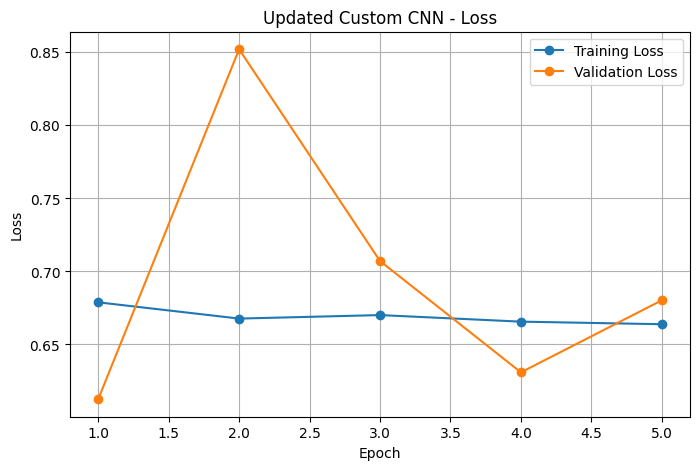

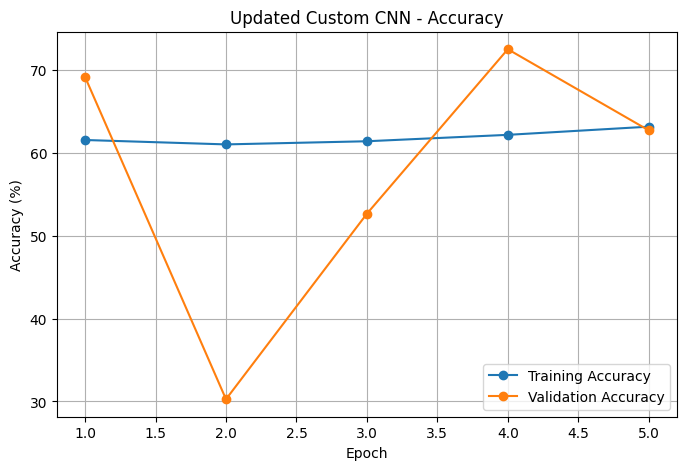

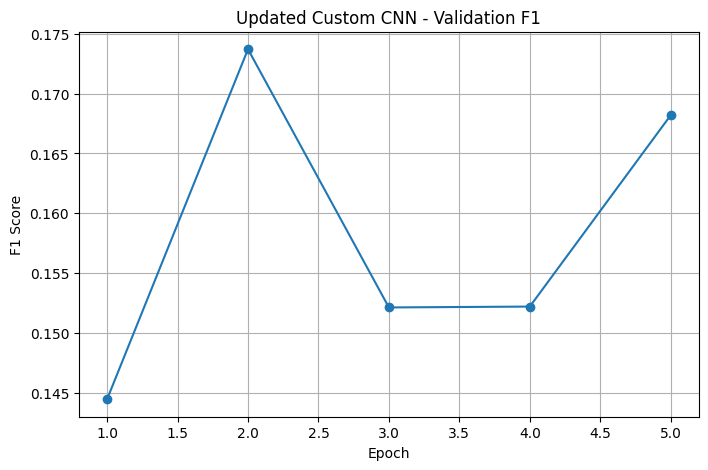

In [23]:

# Step 19: Updated CNN Training Graphs

import matplotlib.pyplot as plt
import numpy as np

epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses,
         marker="o", label="Training Loss")
plt.plot(epochs_range, val_losses,
         marker="o", label="Validation Loss")
plt.title("Updated Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, np.array(train_accuracies)*100,
         marker="o", label="Training Accuracy")
plt.plot(epochs_range, np.array(val_accuracies)*100,
         marker="o", label="Validation Accuracy")
plt.title("Updated Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, val_f1_scores, marker="o")
plt.title("Updated Custom CNN - Validation F1")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.grid(True)
plt.show()


In [24]:

# Step 20: Build ResNet18 Model

import torch
from torch import nn
from torchvision import models

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(weights=weights)

# Freeze pretrained feature extractor
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the classification layer
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Sequential(
    nn.Linear(num_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 2)
)

resnet_model = resnet_model.to(device)

print("ResNet18 Model Created Successfully!")
print("Device:", device)

trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("Trainable Parameters:", trainable_params)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


ResNet18 Model Created Successfully!
Device: cuda
Trainable Parameters: 65922


In [25]:

# Step 21: Prepare ResNet18 DataLoaders

from torchvision import transforms
from torch.utils.data import DataLoader

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

resnet_train_dataset = ForgeryDataset(
    train_df, resnet_transform
)

resnet_val_dataset = ForgeryDataset(
    val_df, resnet_transform
)

resnet_test_dataset = ForgeryDataset(
    test_df, resnet_transform
)

resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(resnet_train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)
print("ResNet18 DataLoaders Created Successfully!")


Image Batch Shape: torch.Size([32, 3, 224, 224])
Label Batch Shape: torch.Size([32])
ResNet18 DataLoaders Created Successfully!


In [26]:

# Step 22: Train ResNet18

import torch
import numpy as np
import copy
from torch import nn
from sklearn.metrics import accuracy_score, f1_score

# Recalculate class weights from training data
counts = np.bincount(
    train_df["label"].to_numpy(), minlength=2
)

weights = len(train_df) / (2 * counts)

resnet_class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

resnet_criterion = nn.CrossEntropyLoss(
    weight=resnet_class_weights
)

# Train the new classification head only
resnet_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet_model.parameters()
    ),
    lr=0.001
)

resnet_epochs = 5

resnet_train_losses = []
resnet_val_losses = []
resnet_train_accs = []
resnet_val_accs = []
resnet_val_f1s = []

best_resnet_f1 = -1
best_resnet_state = None

for epoch in range(resnet_epochs):

    # Training: keep frozen backbone in eval mode
    resnet_model.train()
    resnet_model.eval()
    resnet_model.fc.train()

    train_loss_sum = 0
    train_preds = []
    train_labels = []

    for images, labels in resnet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        resnet_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_preds.extend(
            outputs.argmax(1).detach().cpu().tolist()
        )
        train_labels.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / len(resnet_train_dataset)
    train_acc = accuracy_score(train_labels, train_preds)

    # Validation
    resnet_model.eval()

    val_loss_sum = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for images, labels in resnet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_preds.extend(outputs.argmax(1).cpu().tolist())
            val_labels.extend(labels.cpu().tolist())

    val_loss = val_loss_sum / len(resnet_val_dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(
        val_labels, val_preds,
        pos_label=1, zero_division=0
    )

    resnet_train_losses.append(train_loss)
    resnet_val_losses.append(val_loss)
    resnet_train_accs.append(train_acc)
    resnet_val_accs.append(val_acc)
    resnet_val_f1s.append(val_f1)

    if val_f1 > best_resnet_f1:
        best_resnet_f1 = val_f1
        best_resnet_state = copy.deepcopy(
            resnet_model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{resnet_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val F1: {val_f1:.4f}",
        flush=True
    )

# Restore and save the best model
resnet_model.load_state_dict(best_resnet_state)

torch.save(
    resnet_model.state_dict(),
    "/content/best_resnet18.pth"
)

print("\nResNet18 Training Completed!")
print(f"Best Validation F1: {best_resnet_f1:.4f}")
print("Best ResNet18 Model Saved!")


Epoch [1/5] | Train Loss: 0.6363 | Train Acc: 63.75% | Val Loss: 0.5859 | Val Acc: 68.36% | Val F1: 0.2620
Epoch [2/5] | Train Loss: 0.5631 | Train Acc: 71.48% | Val Loss: 0.5359 | Val Acc: 72.67% | Val F1: 0.2811
Epoch [3/5] | Train Loss: 0.5296 | Train Acc: 73.25% | Val Loss: 0.7001 | Val Acc: 56.99% | Val F1: 0.2434
Epoch [4/5] | Train Loss: 0.5201 | Train Acc: 74.44% | Val Loss: 0.4464 | Val Acc: 78.70% | Val F1: 0.2127
Epoch [5/5] | Train Loss: 0.4932 | Train Acc: 75.85% | Val Loss: 0.4186 | Val Acc: 81.30% | Val F1: 0.2521

ResNet18 Training Completed!
Best Validation F1: 0.2811
Best ResNet18 Model Saved!


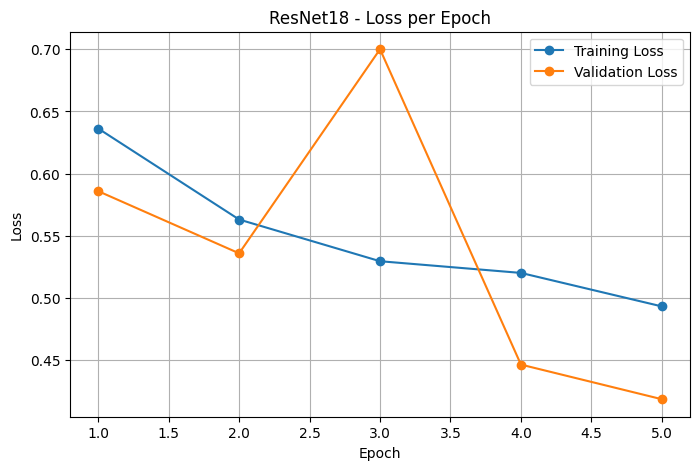

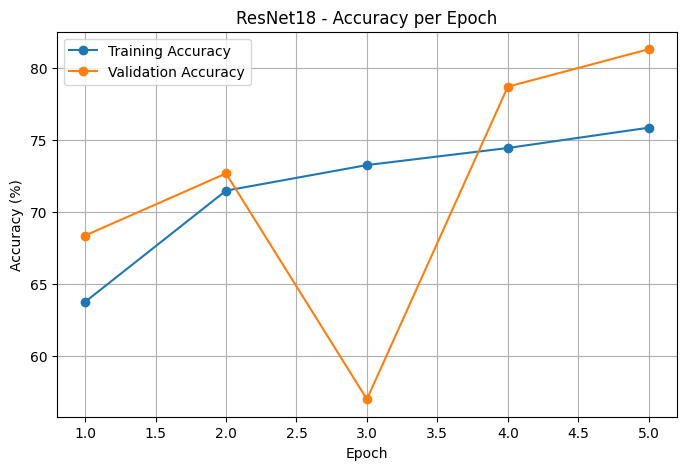

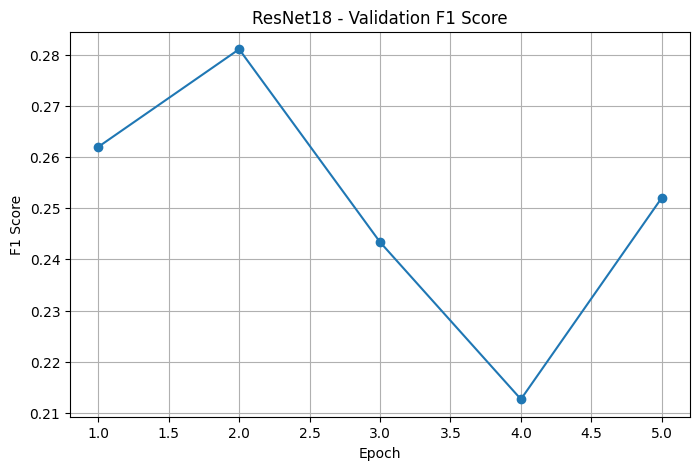

In [27]:

# Step 23: ResNet18 Training Graphs

import matplotlib.pyplot as plt
import numpy as np

epoch_range = range(1, resnet_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_range, resnet_train_losses,
         marker="o", label="Training Loss")
plt.plot(epoch_range, resnet_val_losses,
         marker="o", label="Validation Loss")
plt.title("ResNet18 - Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epoch_range, np.array(resnet_train_accs)*100,
         marker="o", label="Training Accuracy")
plt.plot(epoch_range, np.array(resnet_val_accs)*100,
         marker="o", label="Validation Accuracy")
plt.title("ResNet18 - Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epoch_range, resnet_val_f1s, marker="o")
plt.title("ResNet18 - Validation F1 Score")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.grid(True)
plt.show()


ResNet18 Classification Report:
              precision    recall  f1-score   support

   Authentic       0.93      0.75      0.83      1303
    Tampered       0.20      0.50      0.28       157

    accuracy                           0.73      1460
   macro avg       0.56      0.63      0.56      1460
weighted avg       0.85      0.73      0.77      1460

Balanced Accuracy: 0.6256
ROC-AUC: 0.6853


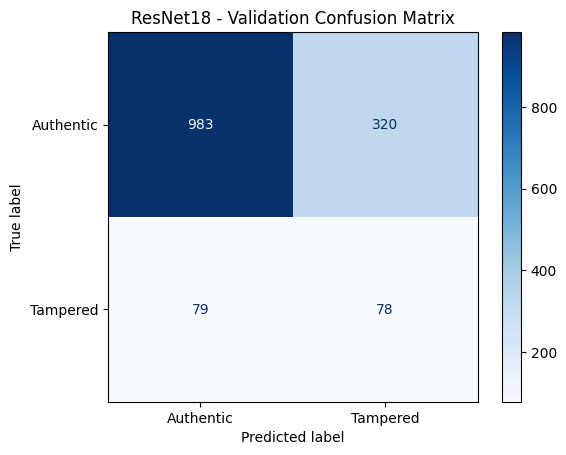

In [28]:

# Step 24: ResNet18 Validation Evaluation

import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score
)

resnet_model.eval()

resnet_labels = []
resnet_predictions = []
resnet_probabilities = []

with torch.no_grad():
    for images, labels in resnet_val_loader:
        images = images.to(device)

        outputs = resnet_model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        resnet_labels.extend(labels.numpy())
        resnet_predictions.extend(preds.cpu().numpy())
        resnet_probabilities.extend(
            probs[:, 1].cpu().numpy()
        )

print("ResNet18 Classification Report:")
print(classification_report(
    resnet_labels,
    resnet_predictions,
    target_names=["Authentic", "Tampered"],
    zero_division=0
))

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(
        resnet_labels, resnet_predictions
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        resnet_labels, resnet_probabilities
    ), 4)
)

cm = confusion_matrix(
    resnet_labels,
    resnet_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Authentic", "Tampered"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 - Validation Confusion Matrix")
plt.show()


Updated CNN Classification Report:
              precision    recall  f1-score   support

   Authentic       0.87      0.26      0.40      1303
    Tampered       0.10      0.68      0.17       157

    accuracy                           0.30      1460
   macro avg       0.48      0.47      0.29      1460
weighted avg       0.79      0.30      0.37      1460

Balanced Accuracy: 0.4693
ROC-AUC: 0.4761


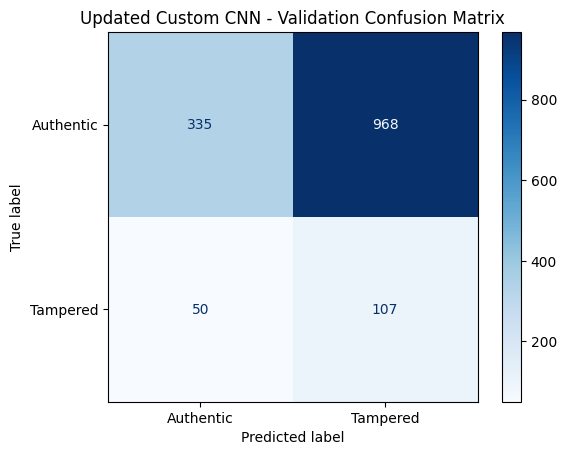

In [29]:

# Step 25: Evaluate Updated Custom CNN

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score
)

model.eval()

cnn_labels = []
cnn_predictions = []
cnn_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        cnn_labels.extend(labels.numpy())
        cnn_predictions.extend(preds.cpu().numpy())
        cnn_probabilities.extend(
            probs[:, 1].cpu().numpy()
        )

print("Updated CNN Classification Report:")
print(classification_report(
    cnn_labels,
    cnn_predictions,
    target_names=["Authentic", "Tampered"],
    zero_division=0
))

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(
        cnn_labels, cnn_predictions
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        cnn_labels, cnn_probabilities
    ), 4)
)

cm = confusion_matrix(
    cnn_labels, cnn_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Authentic", "Tampered"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Updated Custom CNN - Validation Confusion Matrix")
plt.show()


In [31]:

# Step 26: Save Project Results

from google.colab import drive
from pathlib import Path
import shutil
import json
import pandas as pd

# Connect Google Drive
drive.mount("/content/drive")

# Create project folder
save_dir = Path(
    "/content/drive/MyDrive/ARTI502_Forgery_Project"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Save dataset splits
train_df.to_csv(save_dir / "train_split.csv", index=False)
val_df.to_csv(save_dir / "val_split.csv", index=False)
test_df.to_csv(save_dir / "test_split.csv", index=False)

# Save trained models
model_files = [
    "/content/best_custom_cnn_updated.pth",
    "/content/best_resnet18.pth"
]

for file_path in model_files:
    source = Path(file_path)
    if source.exists():
        shutil.copy2(source, save_dir / source.name)
        print("Saved:", source.name)
    else:
        print("Missing model:", source.name)

# Save validation comparison
results = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Accuracy": 0.3027,
        "Tampered F1": 0.1737,
        "Balanced Accuracy": 0.4693,
        "ROC-AUC": 0.4761
    },
    {
        "Model": "ResNet18",
        "Accuracy": 0.7267,
        "Tampered F1": 0.2811,
        "Balanced Accuracy": 0.6256,
        "ROC-AUC": 0.6853
    }
])

results.to_csv(
    save_dir / "validation_comparison.csv",
    index=False
)

print("\nProject files saved to:")
print(save_dir)


Mounted at /content/drive
Saved: best_custom_cnn_updated.pth
Saved: best_resnet18.pth

Project files saved to:
/content/drive/MyDrive/ARTI502_Forgery_Project


In [32]:

# Step 27: Inspect Source ID Connections

import re
from pathlib import Path
from collections import Counter

largest_id = jpg_df["group_id"].value_counts().idxmax()

largest_df = jpg_df[
    jpg_df["group_id"] == largest_id
]

source_counter = Counter()

for path in largest_df["image_path"]:
    name = Path(path).stem.lower()

    source_ids = set(
        re.findall(r"([a-z]{3})_?(\d{5})", name)
    )

    source_counter.update(source_ids)

print("Largest group size:", len(largest_df))

print("\nMost common source identifiers:")
for key, count in source_counter.most_common(20):
    print(key, ":", count)

print("\nExample tampered filenames:")
examples = largest_df[
    largest_df["label"] == 1
]["image_path"].head(10)

for path in examples:
    print(Path(path).name)


Largest group size: 1773

Most common source identifiers:
('cha', '00070') : 39
('nat', '00059') : 37
('nat', '00097') : 36
('cha', '00062') : 34
('nat', '00095') : 33
('nat', '00013') : 28
('cha', '00086') : 26
('art', '00092') : 25
('nat', '10156') : 25
('nat', '10124') : 23
('ani', '00070') : 23
('nat', '10123') : 23
('ani', '00100') : 20
('nat', '10122') : 19
('ani', '10123') : 19
('cha', '00063') : 18
('nat', '00062') : 18
('nat', '10159') : 18
('cha', '10110') : 17
('art', '00025') : 17

Example tampered filenames:
Tp_D_NRN_M_B_nat00038_cha00072_11459.jpg
Tp_D_NNN_S_N_arc00060_arc00062_11493.jpg
Tp_D_NRN_M_N_nat10151_cha00070_12108.jpg
Tp_D_CNN_S_B_art10110_cha10110_11564.jpg
Tp_D_NRN_M_N_nat10134_nat10124_11913.jpg
Tp_D_NRN_M_N_nat10144_nat10145_11964.jpg
Tp_D_NRN_S_N_arc00016_arc00020_11703.jpg
Tp_D_NRN_S_N_cha10108_cha00062_11584.jpg
Tp_D_CRN_M_N_nat00032_art00025_11427.jpg
Tp_D_NRN_S_N_nat00040_art00025_11472.jpg


In [33]:

# Step 28: Validate Source Identifiers

import re
from pathlib import Path

# Collect identifiers from authentic image filenames
authentic_ids = set()

for path in jpg_df[jpg_df["label"] == 0]["image_path"]:
    name = Path(path).stem.lower()
    matches = re.findall(
        r"([a-z]{3})_?(\d{5})", name
    )
    authentic_ids.update(matches)

# Extract source references from tampered filenames
tampered_refs = set()

for path in jpg_df[jpg_df["label"] == 1]["image_path"]:
    name = Path(path).stem.lower()
    matches = re.findall(
        r"([a-z]{3})_?(\d{5})", name
    )
    tampered_refs.update(matches)

matched = tampered_refs & authentic_ids
unmatched = tampered_refs - authentic_ids

print("Authentic source IDs:", len(authentic_ids))
print("Tampered source references:", len(tampered_refs))
print("Matched references:", len(matched))
print("Unmatched references:", len(unmatched))

if tampered_refs:
    print(
        "Reference match percentage:",
        round(len(matched) / len(tampered_refs) * 100, 2),
        "%"
    )

print("\nExamples of unmatched references:")
for item in sorted(unmatched)[:20]:
    print(item)


Authentic source IDs: 7437
Tampered source references: 930
Matched references: 876
Unmatched references: 54
Reference match percentage: 94.19 %

Examples of unmatched references:
('arc', '10120')
('arc', '10121')
('arc', '10122')
('arc', '10123')
('arc', '10124')
('arc', '10125')
('arc', '10126')
('arc', '10127')
('arc', '10128')
('arc', '10129')
('arc', '10130')
('nat', '10131')
('nat', '10132')
('nat', '10133')
('nat', '10134')
('nat', '10135')
('nat', '10136')
('nat', '10137')
('nat', '10138')
('nat', '10139')


In [34]:

# Step 29: Check Unmatched IDs Against All Authentic Images

import re
from pathlib import Path

all_authentic_ids = set()

for path in df[df["label"] == 0]["image_path"]:
    filename = Path(path).stem.lower()

    all_authentic_ids.update(
        re.findall(r"([a-z]{3})_?(\d{5})", filename)
    )

matched_all = tampered_refs & all_authentic_ids
unmatched_all = tampered_refs - all_authentic_ids

print("Total authentic source IDs:", len(all_authentic_ids))
print("Tampered source references:", len(tampered_refs))
print("Matched using all authentic formats:", len(matched_all))
print("Still unmatched:", len(unmatched_all))

print("\nRemaining unmatched IDs:")
for item in sorted(unmatched_all)[:30]:
    print(item)


Total authentic source IDs: 7491
Tampered source references: 930
Matched using all authentic formats: 930
Still unmatched: 0

Remaining unmatched IDs:


In [35]:

# Step 30: Final Dataset Integrity Check

import pandas as pd
from pathlib import Path

splits = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

rows = []

for name, part in splits.items():
    rows.append({
        "Split": name,
        "Total": len(part),
        "Authentic": (part["label"] == 0).sum(),
        "Tampered": (part["label"] == 1).sum(),
        "Tampered %": round(
            (part["label"] == 1).mean() * 100, 2
        )
    })

summary = pd.DataFrame(rows)
display(summary)

# Verify no image-path overlap
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

# Verify source-group separation
assert set(train_df["group_id"]).isdisjoint(
    val_df["group_id"]
)
assert set(train_df["group_id"]).isdisjoint(
    test_df["group_id"]
)
assert set(val_df["group_id"]).isdisjoint(
    test_df["group_id"]
)

# Verify data loaders match current splits
assert len(train_loader.dataset) == len(train_df)
assert len(val_loader.dataset) == len(val_df)
assert len(test_loader.dataset) == len(test_df)

assert len(resnet_train_loader.dataset) == len(train_df)
assert len(resnet_val_loader.dataset) == len(val_df)
assert len(resnet_test_loader.dataset) == len(test_df)

print("All basic integrity checks passed!")


,Split,Total,Authentic,Tampered,Tampered %
0,Training,6584,4835,1749,26.56
1,Validation,1460,1303,157,10.75
2,Testing,1457,1299,158,10.84


All basic integrity checks passed!


,Model,Accuracy,Tampered Precision,Tampered Recall,Tampered F1,Balanced Accuracy,ROC-AUC
0,Custom CNN,0.3027,0.1,0.68,0.1737,0.4693,0.4761
1,ResNet18,0.7267,0.2,0.50,0.2811,0.6256,0.6853


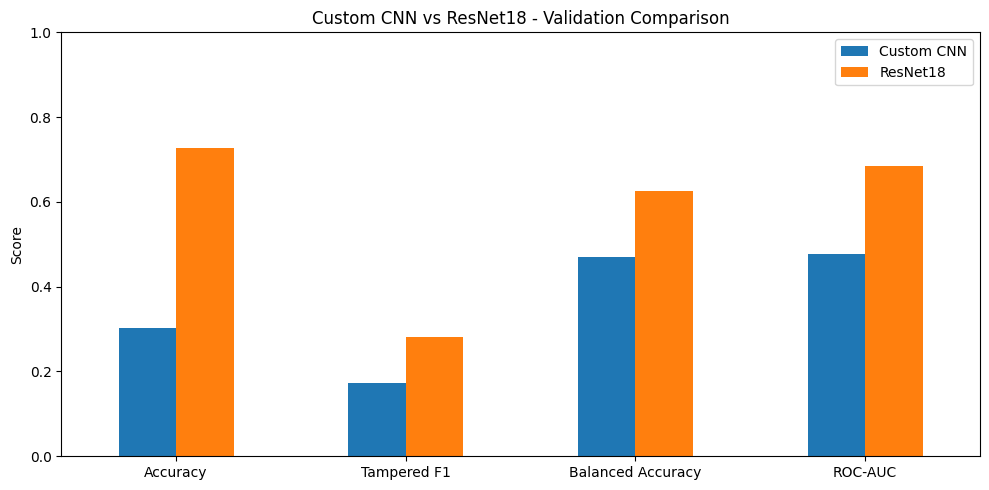

Baseline comparison saved successfully!


In [36]:

# Step 31: Baseline Model Comparison

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet18"],
    "Accuracy": [0.3027, 0.7267],
    "Tampered Precision": [0.10, 0.20],
    "Tampered Recall": [0.68, 0.50],
    "Tampered F1": [0.1737, 0.2811],
    "Balanced Accuracy": [0.4693, 0.6256],
    "ROC-AUC": [0.4761, 0.6853]
})

display(comparison)

comparison.to_csv(
    "/content/drive/MyDrive/ARTI502_Forgery_Project/"
    "baseline_comparison.csv",
    index=False
)

metrics = [
    "Accuracy",
    "Tampered F1",
    "Balanced Accuracy",
    "ROC-AUC"
]

comparison.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Custom CNN vs ResNet18 - Validation Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print("Baseline comparison saved successfully!")


,Threshold,Precision,Recall,F1,Balanced Accuracy
0,0.10,0.1163,0.9936,0.2083,0.5421
1,0.15,0.1256,0.9809,0.2227,0.5791
2,0.20,0.1338,0.9299,0.2340,0.6023
3,0.25,0.1456,0.9045,0.2509,0.6326
4,0.30,0.1528,0.8280,0.2579,0.6373
5,0.35,0.1610,0.7516,0.2652,0.6398
6,0.40,0.1631,0.6306,0.2592,0.6204
7,0.45,0.1730,0.5478,0.2630,0.6162
8,0.50,0.1960,0.4968,0.2811,0.6256
9,0.55,0.2045,0.4076,0.2723,0.6083


Best Threshold: 0.5
Best Validation F1: 0.2811


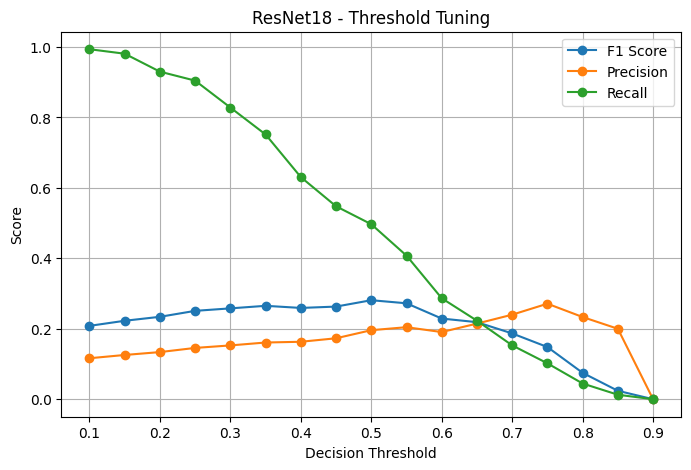

In [37]:

# Step 32: ResNet18 Decision Threshold Tuning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Uses validation probabilities from Step 24
y_true = np.array(resnet_labels)
y_probs = np.array(resnet_probabilities)

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:
    y_pred = (y_probs >= threshold).astype(int)

    results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_true, y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

best_idx = threshold_df["F1"].idxmax()
best_threshold = float(
    threshold_df.loc[best_idx, "Threshold"]
)

print("Best Threshold:", best_threshold)
print(
    "Best Validation F1:",
    round(threshold_df.loc[best_idx, "F1"], 4)
)

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("ResNet18 - Threshold Tuning")
plt.legend()
plt.grid(True)
plt.show()


In [38]:

# Step 33: Save Threshold Tuning Results

from pathlib import Path

save_dir = Path(
    "/content/drive/MyDrive/ARTI502_Forgery_Project"
)

threshold_df.to_csv(
    save_dir / "resnet18_threshold_tuning.csv",
    index=False
)

print("Threshold tuning results saved!")
print("Best Threshold:", best_threshold)
print("Best Validation F1:",
      round(threshold_df["F1"].max(), 4))


Threshold tuning results saved!
Best Threshold: 0.5
Best Validation F1: 0.2811


In [39]:

# Step 34: ResNet18 Learning Rate Tuning

import torch
import numpy as np
import pandas as pd
import copy
from torch import nn
from torchvision import models
from sklearn.metrics import f1_score, accuracy_score

learning_rates = [0.0001, 0.0005, 0.001]
tuning_results = []

# Initialize a common starting model
torch.manual_seed(42)

base_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

for param in base_model.parameters():
    param.requires_grad = False

num_features = base_model.fc.in_features
base_model.fc = nn.Sequential(
    nn.Linear(num_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 2)
)

initial_state = copy.deepcopy(base_model.state_dict())

# Use weights from training split
counts = np.bincount(
    train_df["label"].to_numpy(),
    minlength=2
)

class_weights = torch.tensor(
    len(train_df) / (2 * counts),
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

best_overall_f1 = -1
best_tuned_state = None
best_tuned_lr = None

for lr in learning_rates:
    print(f"\nLearning Rate: {lr}")

    torch.manual_seed(42)
    current_model = models.resnet18(weights=None)

    for param in current_model.parameters():
        param.requires_grad = False

    current_model.fc = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 2)
    )

    current_model.load_state_dict(initial_state)
    current_model = current_model.to(device)

    optimizer = torch.optim.Adam(
        current_model.fc.parameters(),
        lr=lr
    )

    for epoch in range(3):
        current_model.eval()
        current_model.fc.train()

        for images, labels in resnet_train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = current_model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        current_model.eval()
        preds, targets = [], []

        with torch.no_grad():
            for images, labels in resnet_val_loader:
                images = images.to(device)

                outputs = current_model(images)
                preds.extend(
                    outputs.argmax(1).cpu().tolist()
                )
                targets.extend(labels.tolist())

        val_f1 = f1_score(
            targets, preds,
            pos_label=1, zero_division=0
        )
        val_acc = accuracy_score(targets, preds)

        tuning_results.append({
            "Learning Rate": lr,
            "Epoch": epoch + 1,
            "Validation Accuracy": val_acc,
            "Validation F1": val_f1
        })

        print(
            f"Epoch {epoch+1}/3 | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Val F1: {val_f1:.4f}",
            flush=True
        )

        if val_f1 > best_overall_f1:
            best_overall_f1 = val_f1
            best_tuned_lr = lr
            best_tuned_state = copy.deepcopy(
                current_model.state_dict()
            )

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

print("\nBest Learning Rate:", best_tuned_lr)
print("Best Validation F1:", round(best_overall_f1, 4))

# Save tuning results and best model to Google Drive
from pathlib import Path

save_dir = Path(
    "/content/drive/MyDrive/ARTI502_Forgery_Project"
)

tuning_df.to_csv(
    save_dir / "resnet18_learning_rate_tuning.csv",
    index=False
)

torch.save(
    best_tuned_state,
    save_dir / "best_resnet18_tuned.pth"
)

print("Tuning results and best model saved!")



Learning Rate: 0.0001
Epoch 1/3 | Val Acc: 80.21% | Val F1: 0.1905
Epoch 2/3 | Val Acc: 56.78% | Val F1: 0.2497
Epoch 3/3 | Val Acc: 76.51% | Val F1: 0.2560

Learning Rate: 0.0005
Epoch 1/3 | Val Acc: 78.08% | Val F1: 0.2417
Epoch 2/3 | Val Acc: 66.37% | Val F1: 0.2639
Epoch 3/3 | Val Acc: 71.51% | Val F1: 0.2598

Learning Rate: 0.001
Epoch 1/3 | Val Acc: 77.12% | Val F1: 0.2269
Epoch 2/3 | Val Acc: 71.37% | Val F1: 0.2641
Epoch 3/3 | Val Acc: 70.34% | Val F1: 0.2417


,Learning Rate,Epoch,Validation Accuracy,Validation F1
0,0.0001,1,0.802055,0.190476
1,0.0001,2,0.567808,0.249703
2,0.0001,3,0.765068,0.255965
3,0.0005,1,0.780822,0.241706
4,0.0005,2,0.663699,0.263868
5,0.0005,3,0.715068,0.259786
6,0.0010,1,0.771233,0.226852
7,0.0010,2,0.713699,0.264085
8,0.0010,3,0.703425,0.241681



Best Learning Rate: 0.001
Best Validation F1: 0.2641
Tuning results and best model saved!


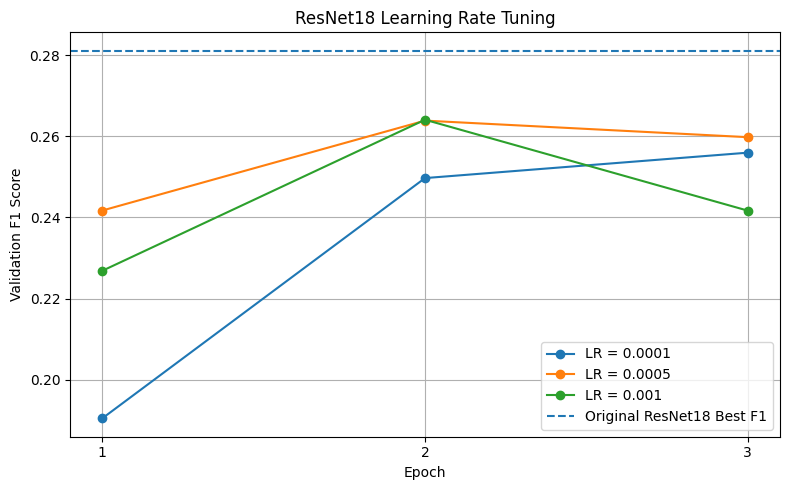

Learning rate comparison figure saved!


In [40]:

# Step 35: Plot Learning Rate Tuning Results

import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(8, 5))

for lr, group in tuning_df.groupby("Learning Rate"):
    plt.plot(
        group["Epoch"],
        group["Validation F1"],
        marker="o",
        label=f"LR = {lr}"
    )

plt.axhline(
    y=0.2811,
    linestyle="--",
    label="Original ResNet18 Best F1"
)

plt.title("ResNet18 Learning Rate Tuning")
plt.xlabel("Epoch")
plt.ylabel("Validation F1 Score")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(True)
plt.tight_layout()

save_dir = Path(
    "/content/drive/MyDrive/ARTI502_Forgery_Project"
)

plt.savefig(
    save_dir / "resnet18_lr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Learning rate comparison figure saved!")


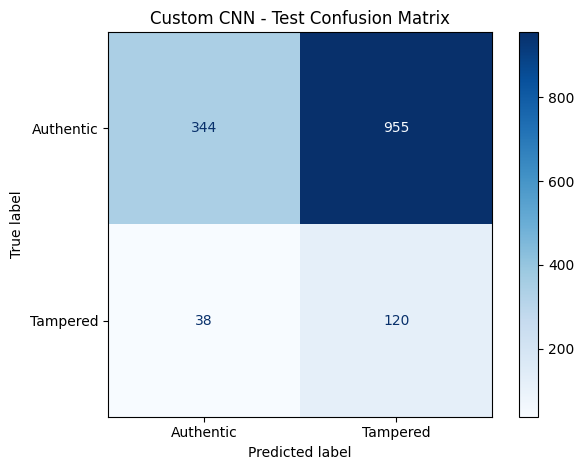

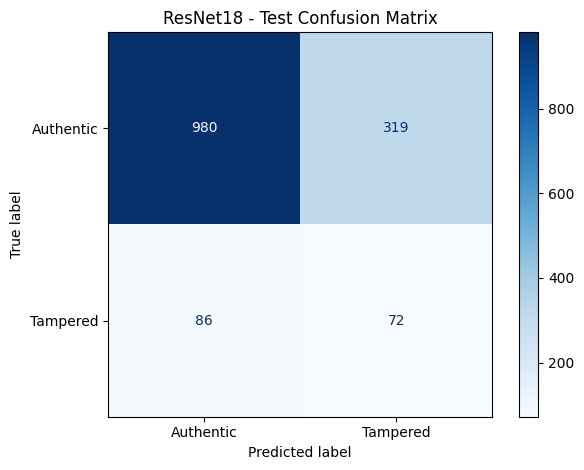

Final Test Results:


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC
0,Custom CNN,0.3185,0.1116,0.7595,0.1946,0.5122,0.5617
1,ResNet18,0.7220,0.1841,0.4557,0.2623,0.6051,0.6858


Test results saved successfully!


In [41]:

# Step 36: Final Test Evaluation

import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

save_dir = Path(
    "/content/drive/MyDrive/ARTI502_Forgery_Project"
)

# Load the best saved models
model.load_state_dict(
    torch.load(
        save_dir / "best_custom_cnn_updated.pth",
        map_location=device,
        weights_only=True
    )
)

resnet_model.load_state_dict(
    torch.load(
        save_dir / "best_resnet18.pth",
        map_location=device,
        weights_only=True
    )
)

def evaluate_test(net, loader, name):
    net.eval()

    actual = []
    predicted = []
    probabilities = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = net(images)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = (probs >= 0.5).long()

            actual.extend(labels.tolist())
            predicted.extend(preds.cpu().tolist())
            probabilities.extend(probs.cpu().tolist())

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "ROC-AUC": roc_auc_score(
            actual, probabilities
        )
    }

    cm = confusion_matrix(
        actual, predicted, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Authentic", "Tampered"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(
        save_dir / f"{filename}_test_cm.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

    return metrics


# Evaluate both models
cnn_result = evaluate_test(
    model, test_loader, "Custom CNN"
)

resnet_result = evaluate_test(
    resnet_model, resnet_test_loader, "ResNet18"
)

# Results comparison
final_results = pd.DataFrame([
    cnn_result,
    resnet_result
])

print("Final Test Results:")
display(final_results.round(4))

final_results.to_csv(
    save_dir / "final_test_results.csv",
    index=False
)

print("Test results saved successfully!")
